# Metropolis-adjusted Langevin Algorithm (MALA)

MALA augments the Metropolis-Hastings random walk with a *gradient-driven drift* derived from the unadjusted Langevin diffusion. The proposal is

$$
y = x + \tfrac{1}{2} h^2 \, A \nabla \log\pi(x) + h \, L \, \varepsilon, \qquad \varepsilon \sim \mathcal{N}(0, I),
$$

where the preconditioner $A = L L^\top$ is optional. In high dimensions, the gradient drift drastically improves mixing compared to vanilla random-walk Metropolis.

In [1]:
import sys, os
sys.path.insert(0, os.path.dirname(os.path.abspath('__file__')))
sys.path.insert(0, os.path.dirname(os.path.dirname(os.path.abspath('__file__'))))

import torch
from torch.distributions.multivariate_normal import MultivariateNormal
import matplotlib.pyplot as plt

from mcmc_samplers import (
    MetropolisAdjustedLangevin,
    MetropolisHastings,
    SampleVisualizer,
    diagnostics,
)

## Banana target

We re-use the banana distribution from the introductory example. Importantly, our target now returns a *scalar* tensor and is differentiable with respect to its input.

In [2]:
class Banana:
    def __init__(self):
        self.mvn = MultivariateNormal(torch.zeros(2), torch.tensor([[1.0, 0.9], [0.9, 1.0]]))

    def __call__(self, x):
        y0 = x[..., 0]
        y1 = x[..., 1] + (x[..., 0] + 1.0) ** 2
        return self.mvn.log_prob(torch.stack([y0, y1], dim=-1))

target = Banana()

## Run MALA and a baseline MH

We give both samplers the same starting point and run for the same number of iterations, then compare effective sample size.

In [3]:
x0 = torch.tensor([0.0, -1.0])
N = 10_000

mala = MetropolisAdjustedLangevin(target=target, x0=x0, step_size=0.4, generator=torch.Generator().manual_seed(0))
mh = MetropolisHastings(target=target, x0=x0, cov=torch.eye(2) * 0.4, generator=torch.Generator().manual_seed(0))

mala_samples, _ = mala(N, burn_in=N // 10)
mh_samples, _ = mh(N, burn_in=N // 10)

print(f'MALA acceptance: {100*mala.acceptance_ratio:.1f}%')
print(f'MH   acceptance: {100*mh.acceptance_ratio:.1f}%')

MALA acceptance: 64.3%
MH   acceptance: 37.7%


In [4]:
mala_ess = diagnostics.effective_sample_size(mala_samples)
mh_ess = diagnostics.effective_sample_size(mh_samples)
print(f'MALA ESS (per dim): {mala_ess.tolist()}')
print(f'MH   ESS (per dim): {mh_ess.tolist()}')

MALA ESS (per dim): [104.39830017089844, 113.32582092285156]
MH   ESS (per dim): [82.29866790771484, 74.22782897949219]


## Visualize the marginals

Even on a 2-D problem, the gradient-driven proposal pushes the chain along the banana ridge with far fewer rejections.

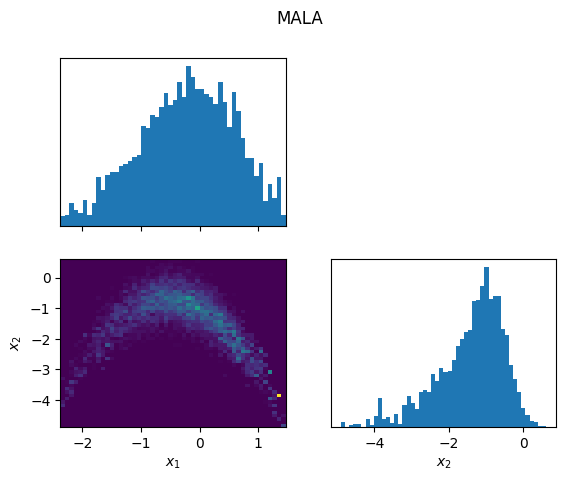

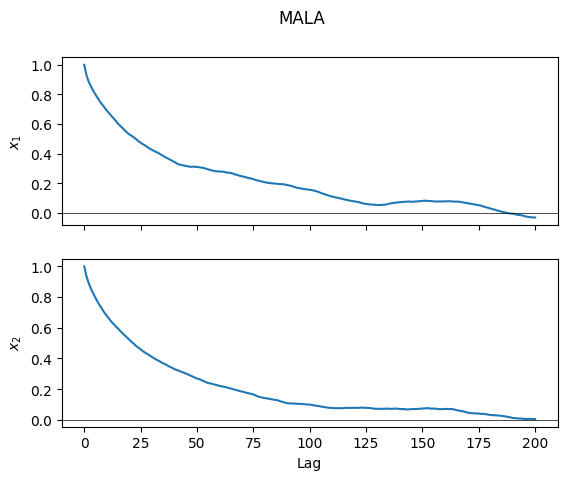

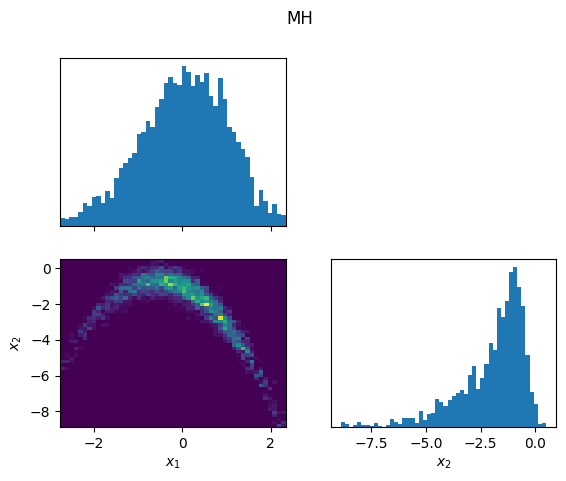

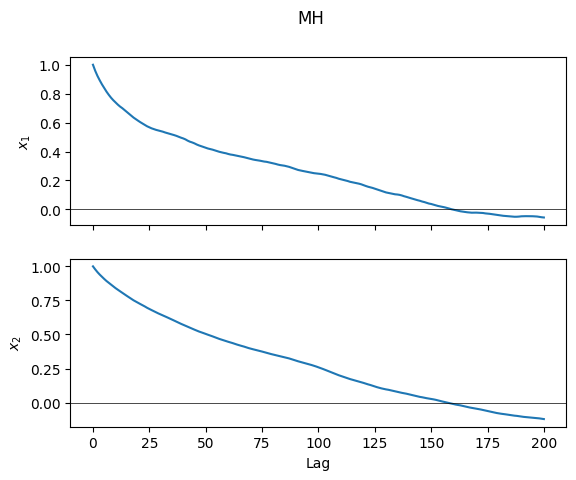

In [5]:
for samples, label in [(mala_samples, 'MALA'), (mh_samples, 'MH')]:
    vis = SampleVisualizer(samples)
    vis.triangular_hist(bins=50, labels=['$x_1$', '$x_2$'], titles=[label])
    vis.autocorrelation(max_lag=200, labels=['$x_1$', '$x_2$'], titles=[label])
plt.show()